### Final Results Hamburg

In [1]:
from sqlalchemy import create_engine
import os
from dotenv import load_dotenv

load_dotenv()

DB_CONFIG = {
    'host': 'localhost',
    'dbname': os.getenv("POSTGRES_DB"),
    'user': os.getenv("POSTGRES_USER"),
    'password': os.getenv("POSTGRES_PASSWORD"),
    'port': 5455
}


engine = create_engine(f"postgresql+psycopg2://{DB_CONFIG['user']}:{DB_CONFIG['password']}@"
                f"{DB_CONFIG['host']}:{DB_CONFIG['port']}/{DB_CONFIG['dbname']}")


In [2]:
import pandas as pd
import geopandas as gpd
query = "SELECT * FROM grid_validation_hamburg"

counts_comp_gdf = gpd.GeoDataFrame.from_postgis(query,engine, geom_col="geom")
counts_comp_gdf

,geom,id,counter_id,count_db,count_sr,count_base,count_base_pois,count_base_dist,count_base_nrd,count_sim
0,"POLYGON ((9.88147 53.47849, 9.88147 53.48383, ...",1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,"POLYGON ((9.88147 53.48383, 9.88147 53.48918, ...",2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,"POLYGON ((9.88147 53.48918, 9.88147 53.49452, ...",3,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,"POLYGON ((9.88147 53.49452, 9.88147 53.49986, ...",4,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,"POLYGON ((9.88147 53.49986, 9.88147 53.50521, ...",5,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...
645,"POLYGON ((10.08808 53.54259, 10.08808 53.54793...",588,7665.0,1341.0,212.0,50.0,30.0,32.0,45.0,53.0
646,"POLYGON ((10.08808 53.54793, 10.08808 53.55327...",589,6813.0,498.0,102.0,1111.0,534.0,276.0,1045.0,1079.0
647,"POLYGON ((10.08808 53.55327, 10.08808 53.5586,...",590,4605.0,941.0,78.0,2118.0,799.0,452.0,1563.0,1462.0
648,"POLYGON ((10.08808 53.5586, 10.08808 53.56394,...",591,10839.0,212.0,14.0,34.0,51.0,23.0,101.0,86.0


In [3]:
counts_comp_gdf = counts_comp_gdf.dropna()
counts_comp_gdf["rank_db"] = counts_comp_gdf["count_db"].rank(ascending=False)
counts_comp_gdf["rank_base"] = counts_comp_gdf["count_base"].rank(ascending=False)
counts_comp_gdf["rank_base_dist"] = counts_comp_gdf["count_base_dist"].rank(ascending=False)
counts_comp_gdf["rank_base_pois"] = counts_comp_gdf["count_base_pois"].rank(ascending=False)
counts_comp_gdf["rank_base_nrd"] = counts_comp_gdf["count_base_nrd"].rank(ascending=False)

counts_comp_gdf["rank_sim"] = counts_comp_gdf["count_sim"].rank(ascending=False)
counts_comp_gdf["rank_sr"] = counts_comp_gdf["count_sr"].rank(ascending=False)
counts_comp_gdf["rank_diff"] = counts_comp_gdf["rank_db"] - counts_comp_gdf["rank_sim"]

counts_comp_df = pd.DataFrame(counts_comp_gdf[["id","count_db","count_base","count_sim","count_sr","count_base_dist","count_base_pois","count_base_nrd","rank_base","rank_db","rank_sr", "rank_base_pois","rank_base_nrd","rank_base_dist",
                                               "rank_sim","rank_diff" ]])
counts_comp_df

,id,count_db,count_base,count_sim,count_sr,count_base_dist,count_base_pois,count_base_nrd,rank_base,rank_db,rank_sr,rank_base_pois,rank_base_nrd,rank_base_dist,rank_sim,rank_diff
317,88,628.0,25.0,64.0,281.0,16.0,14.0,92.0,293.0,238.0,151.5,279.5,258.0,287.0,265.5,-27.5
318,89,1678.0,468.0,836.0,619.0,171.0,377.0,640.0,210.0,167.0,48.0,172.0,178.5,221.0,165.0,2.0
319,90,1653.0,1308.0,1026.0,287.0,382.0,483.0,971.0,159.0,171.0,147.0,156.0,149.0,156.0,151.0,20.0
320,91,1121.0,1132.0,738.0,250.0,325.0,453.0,734.0,169.0,206.0,158.0,159.0,169.0,166.0,169.0,37.0
321,142,4225.0,5081.0,2831.0,1080.0,1447.0,1544.0,3281.0,42.5,45.5,11.0,33.5,29.5,38.5,40.5,5.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
645,588,1341.0,50.0,53.0,212.0,32.0,30.0,45.0,279.5,191.0,171.5,266.0,270.5,267.5,269.5,-78.5
646,589,498.0,1111.0,1079.0,102.0,276.0,534.0,1045.0,173.0,253.0,213.0,147.0,145.0,175.0,146.0,107.0
647,590,941.0,2118.0,1462.0,78.0,452.0,799.0,1563.0,113.0,215.0,231.5,108.0,113.0,144.0,113.0,102.0
648,591,212.0,34.0,86.0,14.0,23.0,51.0,101.0,286.0,282.0,284.0,251.0,249.5,276.0,260.0,22.0


In [4]:
counts_comp_df[["count_db","count_sr","count_base", "count_base_dist",
                "count_base_pois","count_base_nrd",
                "count_sim",]].corr()

,count_db,count_sr,count_base,count_base_dist,count_base_pois,count_base_nrd,count_sim
count_db,1.000000,0.887937,0.582895,0.608298,0.710784,0.725340,0.729422
count_sr,0.887937,1.000000,0.608279,0.657895,0.742742,0.754361,0.750420
count_base,0.582895,0.608279,1.000000,0.940499,0.819643,0.820300,0.808062
count_base_dist,0.608298,0.657895,0.940499,1.000000,0.908171,0.904670,0.895713
count_base_pois,0.710784,0.742742,0.819643,0.908171,1.000000,0.993089,0.987603
count_base_nrd,0.725340,0.754361,0.820300,0.904670,0.993089,1.000000,0.994021
count_sim,0.729422,0.750420,0.808062,0.895713,0.987603,0.994021,1.000000


In [5]:
counts_comp_df[["rank_db","rank_sr","rank_base","rank_base_dist",
                "rank_base_pois","rank_base_nrd",
                "rank_sim",]].corr()

,rank_db,rank_sr,rank_base,rank_base_dist,rank_base_pois,rank_base_nrd,rank_sim
rank_db,1.000000,0.875887,0.516083,0.562552,0.646762,0.657878,0.671645
rank_sr,0.875887,1.000000,0.573139,0.627875,0.707908,0.711285,0.716770
rank_base,0.516083,0.573139,1.000000,0.957241,0.876884,0.872708,0.861043
rank_base_dist,0.562552,0.627875,0.957241,1.000000,0.945782,0.940954,0.936080
rank_base_pois,0.646762,0.707908,0.876884,0.945782,1.000000,0.992507,0.986842
rank_base_nrd,0.657878,0.711285,0.872708,0.940954,0.992507,1.000000,0.993783
rank_sim,0.671645,0.716770,0.861043,0.936080,0.986842,0.993783,1.000000


In [6]:
counts_comp_df[["rank_db","rank_sr","rank_base","rank_base_dist",
                "rank_base_pois","rank_base_nrd",
                "rank_sim",]].corr(method="kendall")

,rank_db,rank_sr,rank_base,rank_base_dist,rank_base_pois,rank_base_nrd,rank_sim
rank_db,1.000000,0.702427,0.363829,0.395099,0.466374,0.478705,0.491678
rank_sr,0.702427,1.000000,0.411894,0.457131,0.528093,0.534165,0.541228
rank_base,0.363829,0.411894,1.000000,0.827944,0.699833,0.690615,0.676995
rank_base_dist,0.395099,0.457131,0.827944,1.000000,0.789941,0.782531,0.771557
rank_base_pois,0.466374,0.528093,0.699833,0.789941,1.000000,0.932002,0.907813
rank_base_nrd,0.478705,0.534165,0.690615,0.782531,0.932002,1.000000,0.938376
rank_sim,0.491678,0.541228,0.676995,0.771557,0.907813,0.938376,1.000000


In [7]:
from scipy.stats import spearmanr

list_sim = []
list_base = []
list_base_pois = []
list_base_nrd = []
list_base_dist = []
list_sr = []

for i in range(10,len(counts_comp_df) + 5, 10):
    counts_comp_df_red = counts_comp_df[counts_comp_df["rank_db"] < i]
    counts_comp_df_red["rank_base"] = counts_comp_df_red["count_base"].rank(ascending=False)
    counts_comp_df_red["rank_base_dist"] = counts_comp_df_red["count_base_dist"].rank(ascending=False)
    counts_comp_df_red["rank_base_pois"] = counts_comp_df_red["count_base_pois"].rank(ascending=False)
    counts_comp_df_red["rank_base_nrd"] = counts_comp_df_red["count_base_nrd"].rank(ascending=False)
    counts_comp_df_red["rank_sim"] = counts_comp_df_red["count_sim"].rank(ascending=False)
    counts_comp_df_red["rank_sr"] = counts_comp_df_red["count_sr"].rank(ascending=False)
    res_sim = spearmanr(counts_comp_df_red["rank_db"], counts_comp_df_red["rank_sim"])
    res_base = spearmanr(counts_comp_df_red["rank_db"], counts_comp_df_red["rank_base"])
    res_base_pois = spearmanr(counts_comp_df_red["rank_db"], counts_comp_df_red["rank_base_pois"])
    res_base_nrd = spearmanr(counts_comp_df_red["rank_db"], counts_comp_df_red["rank_base_nrd"])
    res_base_dist = spearmanr(counts_comp_df_red["rank_db"], counts_comp_df_red["rank_base_dist"])
    res_sr = spearmanr(counts_comp_df_red["rank_db"], counts_comp_df_red["rank_sr"])
    list_base.append(res_base.statistic)
    list_base_pois.append(res_base_pois.statistic)
    list_base_nrd.append(res_base_nrd.statistic)
    list_base_dist.append(res_base_dist.statistic)
    list_sim.append(res_sim.statistic)
    list_sr.append(res_sr.statistic)

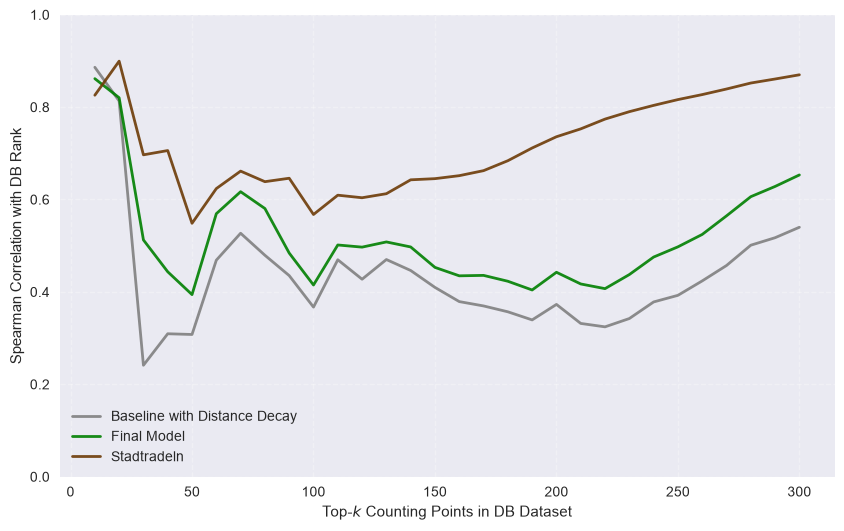

In [9]:
import matplotlib.pyplot as plt
plt.figure(figsize=(10, 6))

x=range(10,len(counts_comp_df) + 5, 10)
#plt.title("Spearman Correlation with Top-K Counting Points of DB Dataset")
plt.xlabel("Top-$k$ Counting Points in DB Dataset")
plt.ylabel("Spearman Correlation with DB Rank")
plt.ylim(0, 1)

plt.style.use('seaborn-v0_8')
plt.grid(True, linestyle='--', alpha=0.3)

plt.plot(x, list_base_dist, label="Baseline with Distance Decay", linewidth =2, alpha=0.9, color="gray")
plt.plot(x, list_sim, label="Final Model",linewidth =2, alpha=0.9, color="green")
plt.plot(x, list_sr, label ="Stadtradeln",linewidth =2,alpha=0.9, color="#6D3B07")
plt.legend()

import tikzplotlib

tikzplotlib.save("figures/revision/db_spearman_corr.tex")

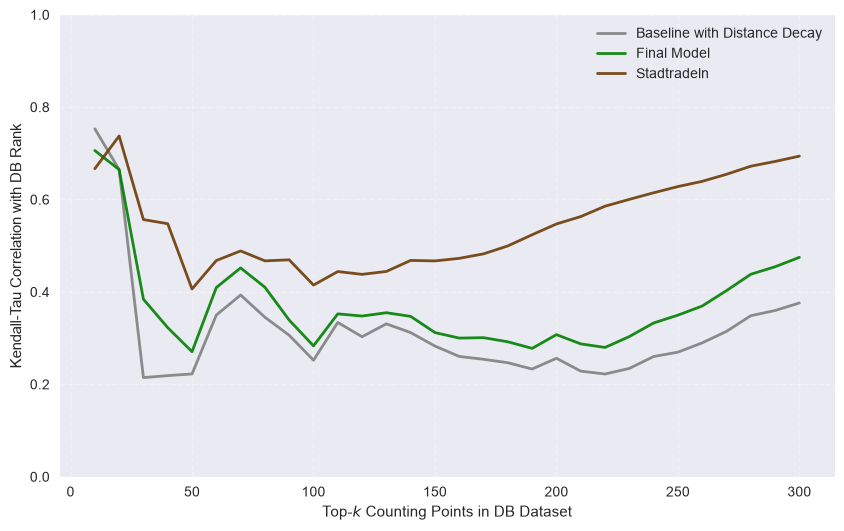

In [11]:
from scipy.stats import kendalltau

list_sim = []
list_base = []
list_base_pois = []
list_base_nrd = []
list_base_dist = []
list_sr = []

for i in range(10,len(counts_comp_df) + 5, 10):
    counts_comp_df_red = counts_comp_df[counts_comp_df["rank_db"] < i]
    counts_comp_df_red["rank_base"] = counts_comp_df_red["count_base"].rank(ascending=False)
    counts_comp_df_red["rank_base_pois"] = counts_comp_df_red["count_base_pois"].rank(ascending=False)
    counts_comp_df_red["rank_base_nrd"] = counts_comp_df_red["count_base_nrd"].rank(ascending=False)
    counts_comp_df_red["rank_base_dist"] = counts_comp_df_red["count_base_dist"].rank(ascending=False)
    counts_comp_df_red["rank_sim"] = counts_comp_df_red["count_sim"].rank(ascending=False)
    counts_comp_df_red["rank_sr"] = counts_comp_df_red["count_sr"].rank(ascending=False)
    res_sim = kendalltau(counts_comp_df_red["rank_db"], counts_comp_df_red["rank_sim"])
    res_base = kendalltau(counts_comp_df_red["rank_db"], counts_comp_df_red["rank_base"])
    res_base_pois = kendalltau(counts_comp_df_red["rank_db"], counts_comp_df_red["rank_base_pois"])
    res_base_nrd = kendalltau(counts_comp_df_red["rank_db"], counts_comp_df_red["rank_base_nrd"])
    res_base_dist = kendalltau(counts_comp_df_red["rank_db"], counts_comp_df_red["rank_base_dist"])
    res_sr = kendalltau(counts_comp_df_red["rank_db"], counts_comp_df_red["rank_sr"])
    list_base.append(res_base.statistic)
    list_base_pois.append(res_base_pois.statistic)
    list_base_nrd.append(res_base_nrd.statistic)
    list_base_dist.append(res_base_dist.statistic)
    list_sim.append(res_sim.statistic)
    list_sr.append(res_sr.statistic)

import matplotlib.pyplot as plt
plt.figure(figsize=(10, 6))

x=range(10,len(counts_comp_df) + 5, 10)
#plt.title("Kendall-Tau Correlation with Top-K Counting Points of DB Dataset")
plt.xlabel("Top-$k$ Counting Points in DB Dataset")
plt.ylabel("Kendall-Tau Correlation with DB Rank")
plt.ylim(0, 1)

plt.style.use('seaborn-v0_8')
plt.grid(True, linestyle='--', alpha=0.3)

plt.plot(x, list_base_dist, label="Baseline with Distance Decay", linewidth =2, alpha=0.9, color="gray")
plt.plot(x, list_sim, label="Final Model",linewidth =2, alpha=0.9, color="green")
plt.plot(x, list_sr, label ="Stadtradeln",linewidth =2,alpha=0.9, color="#6D3B07")
plt.legend()
plt.savefig("figures/revision/db_kendalltau_corr")


import tikzplotlib

tikzplotlib.save("figures/revision/db_kendalltau_corr.tex")

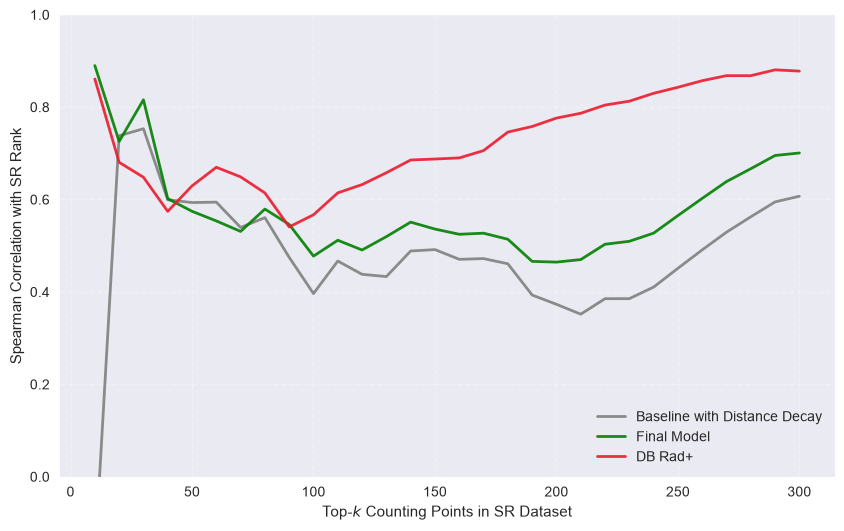

In [10]:
from scipy.stats import spearmanr

list_sim = []
list_base = []
list_base_pois = []
list_base_nrd = []
list_base_dist = []
list_sr = []

for i in range(10,len(counts_comp_df) + 5, 10):
    counts_comp_df_red = counts_comp_df[counts_comp_df["rank_sr"] < i]
    counts_comp_df_red["rank_base"] = counts_comp_df_red["count_base"].rank(ascending=False)
    counts_comp_df_red["rank_base_pois"] = counts_comp_df_red["count_base_pois"].rank(ascending=False)
    counts_comp_df_red["rank_base_nrd"] = counts_comp_df_red["count_base_nrd"].rank(ascending=False)
    counts_comp_df_red["rank_base_dist"] = counts_comp_df_red["count_base_dist"].rank(ascending=False)
    counts_comp_df_red["rank_sim"] = counts_comp_df_red["count_sim"].rank(ascending=False)
    counts_comp_df_red["rank_sr"] = counts_comp_df_red["count_sr"].rank(ascending=False)
    res_sim = spearmanr(counts_comp_df_red["rank_sr"], counts_comp_df_red["rank_sim"])
    res_base = spearmanr(counts_comp_df_red["rank_sr"], counts_comp_df_red["rank_base"])
    res_base_pois = spearmanr(counts_comp_df_red["rank_sr"], counts_comp_df_red["rank_base_pois"])
    res_base_nrd = spearmanr(counts_comp_df_red["rank_sr"], counts_comp_df_red["rank_base_nrd"])
    res_base_dist = spearmanr(counts_comp_df_red["rank_sr"], counts_comp_df_red["rank_base_dist"])
    res_sr = spearmanr(counts_comp_df_red["rank_db"], counts_comp_df_red["rank_sr"])
    list_base.append(res_base.statistic)
    list_base_pois.append(res_base_pois.statistic)
    list_base_nrd.append(res_base_nrd.statistic)
    list_base_dist.append(res_base_dist.statistic)
    list_sim.append(res_sim.statistic)
    list_sr.append(res_sr.statistic)

import matplotlib.pyplot as plt
plt.figure(figsize=(10, 6))

x=range(10,len(counts_comp_df) + 5, 10)
#plt.title("Spearman Correlation with Top-K Counting Points of SR Dataset")
plt.xlabel("Top-$k$ Counting Points in SR Dataset")
plt.ylabel("Spearman Correlation with SR Rank")
plt.ylim(0, 1)

plt.style.use('seaborn-v0_8')
plt.grid(True, linestyle='--', alpha=0.3)

plt.plot(x, list_base_dist, label="Baseline with Distance Decay", linewidth =2, alpha=0.9, color="gray")
plt.plot(x, list_sim, label="Final Model",linewidth =2, alpha=0.9, color="green")
plt.plot(x, list_sr, label ="DB Rad+",linewidth =2,alpha=0.9, color="#EC1B2D")
plt.legend()
plt.savefig("figures/revision/sr_spearman_corr")

import tikzplotlib

tikzplotlib.save("figures/revision/sr_spearman_corr.tex")

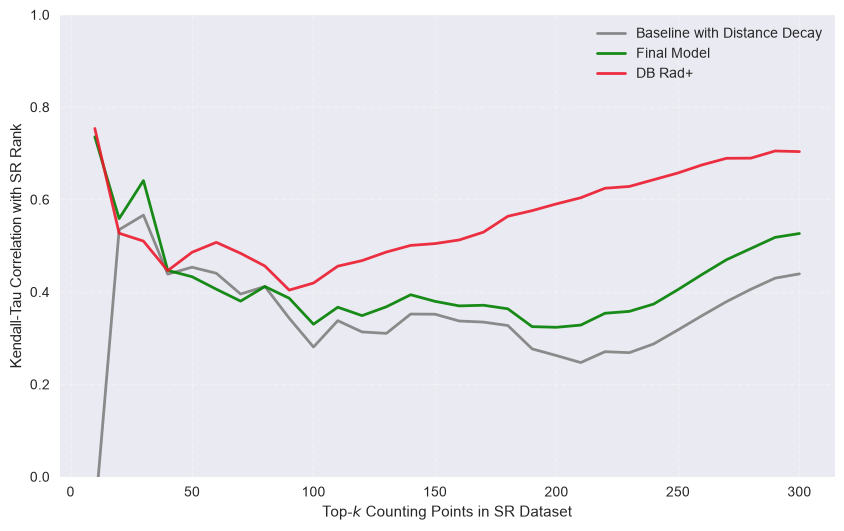

In [ ]:
from scipy.stats import kendalltau

list_sim = []
list_base = []
list_base_pois = []
list_base_nrd = []
list_base_dist = []
list_sr = []

for i in range(10,len(counts_comp_df) + 5, 10):
    counts_comp_df_red = counts_comp_df[counts_comp_df["rank_sr"] < i]
    counts_comp_df_red["rank_base"] = counts_comp_df_red["count_base"].rank(ascending=False)
    counts_comp_df_red["rank_base_pois"] = counts_comp_df_red["count_base_pois"].rank(ascending=False)
    counts_comp_df_red["rank_base_nrd"] = counts_comp_df_red["count_base_nrd"].rank(ascending=False)
    counts_comp_df_red["rank_base_dist"] = counts_comp_df_red["count_base_dist"].rank(ascending=False)
    counts_comp_df_red["rank_sim"] = counts_comp_df_red["count_sim"].rank(ascending=False)
    counts_comp_df_red["rank_sr"] = counts_comp_df_red["count_sr"].rank(ascending=False)
    res_sim = kendalltau(counts_comp_df_red["rank_sr"], counts_comp_df_red["rank_sim"])
    res_base = kendalltau(counts_comp_df_red["rank_sr"], counts_comp_df_red["rank_base"])
    res_base_pois = kendalltau(counts_comp_df_red["rank_sr"], counts_comp_df_red["rank_base_pois"])
    res_base_nrd = kendalltau(counts_comp_df_red["rank_sr"], counts_comp_df_red["rank_base_nrd"])
    res_base_dist = kendalltau(counts_comp_df_red["rank_sr"], counts_comp_df_red["rank_base_dist"])
    res_sr = kendalltau(counts_comp_df_red["rank_db"], counts_comp_df_red["rank_sr"])
    list_base.append(res_base.statistic)
    list_base_pois.append(res_base_pois.statistic)
    list_base_nrd.append(res_base_nrd.statistic)
    list_base_dist.append(res_base_dist.statistic)
    list_sim.append(res_sim.statistic)
    list_sr.append(res_sr.statistic)

import matplotlib.pyplot as plt
plt.figure(figsize=(10, 6))

x=range(10,len(counts_comp_df) + 5, 10)
#plt.title("Kendall-Tau Correlation with Top-K Counting Points of SR Dataset")
plt.xlabel("Top-$k$ Counting Points in SR Dataset")
plt.ylabel("Kendall-Tau Correlation with SR Rank")
plt.ylim(0, 1)

plt.style.use('seaborn-v0_8')
plt.grid(True, linestyle='--', alpha=0.3)

plt.plot(x, list_base_dist, label="Baseline with Distance Decay", linewidth =2, alpha=0.9, color="gray")
plt.plot(x, list_sim, label="Final Model",linewidth =2, alpha=0.9, color="green")
plt.plot(x, list_sr, label ="DB Rad+",linewidth =2,alpha=0.9, color="#EC1B2D")
plt.legend()
plt.savefig("figures/revision/sr_kendalltau_corr")

import tikzplotlib

tikzplotlib.save("figures/revision/sr_kendalltau_corr.tex")

In [17]:
from scipy.stats import pearsonr

list_sim = []
list_base = []
list_base_pois = []
list_base_nrd = []
list_base_dist = []
list_sr = []

for i in range(10,len(counts_comp_df) + 5, 10):
    counts_comp_df_red = counts_comp_df[counts_comp_df["rank_db"] < i]
    counts_comp_df_red["rank_base"] = counts_comp_df_red["count_base"].rank(ascending=False)
    counts_comp_df_red["rank_base_pois"] = counts_comp_df_red["count_base_pois"].rank(ascending=False)
    counts_comp_df_red["rank_base_nrd"] = counts_comp_df_red["count_base_nrd"].rank(ascending=False)
    counts_comp_df_red["rank_base_dist"] = counts_comp_df_red["count_base_dist"].rank(ascending=False)
    counts_comp_df_red["rank_sim"] = counts_comp_df_red["count_sim"].rank(ascending=False)
    counts_comp_df_red["rank_sr"] = counts_comp_df_red["count_sr"].rank(ascending=False)
    res_sim = pearsonr(counts_comp_df_red["count_db"], counts_comp_df_red["count_sim"])
    res_base = pearsonr(counts_comp_df_red["count_db"], counts_comp_df_red["count_base_dist"])
    res_sr = pearsonr(counts_comp_df_red["count_db"], counts_comp_df_red["count_sr"])
    list_base.append(res_base.statistic)
    list_base_pois.append(res_base_pois.statistic)
    list_base_nrd.append(res_base_nrd.statistic)
    list_base_dist.append(res_base_dist.statistic)
    list_sim.append(res_sim.statistic)
    list_sr.append(res_sr.statistic)

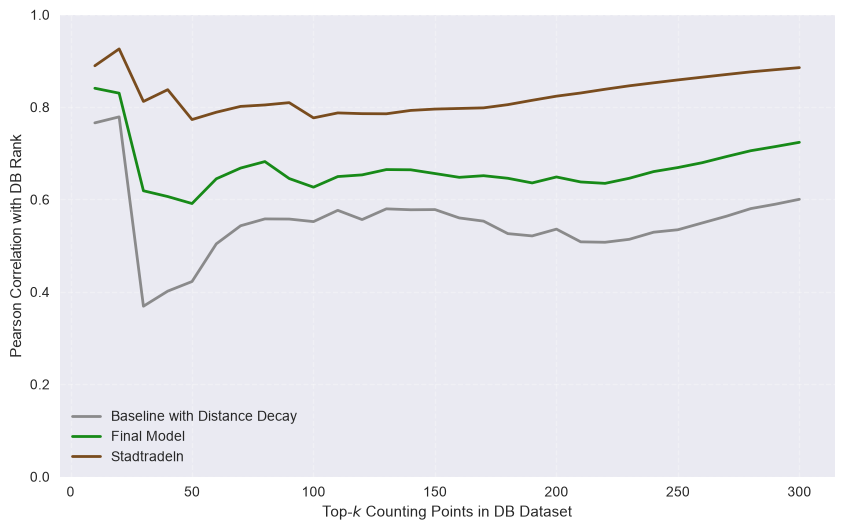

In [19]:
import matplotlib.pyplot as plt
plt.figure(figsize=(10, 6))

x=range(10,len(counts_comp_df) + 5, 10)
#plt.title("Pearson Correlation with Top-K Counting Points of DB Dataset")
plt.xlabel("Top-$k$ Counting Points in DB Dataset")
plt.ylabel("Pearson Correlation with DB Rank")
plt.ylim(0, 1)

plt.style.use('seaborn-v0_8')
plt.grid(True, linestyle='--', alpha=0.3)

plt.plot(x, list_base, label="Baseline with Distance Decay", linewidth =2, alpha=0.9, color="gray")
plt.plot(x, list_sim, label="Final Model",linewidth =2, alpha=0.9, color="green")
plt.plot(x, list_sr, label ="Stadtradeln",linewidth =2,alpha=0.9, color="#6D3B07")
plt.legend()
plt.savefig("figures/revision/db_pearson_corr")

import tikzplotlib

tikzplotlib.save("figures/revision/db_pearson_corr.tex")

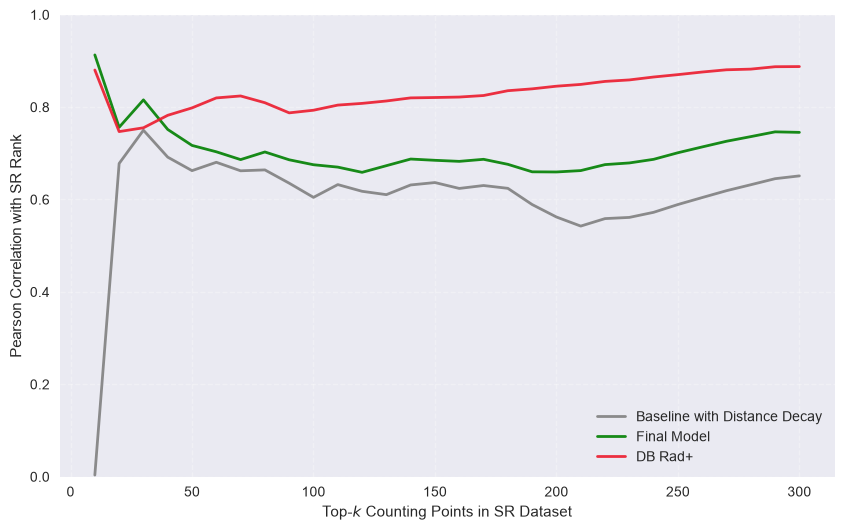

In [21]:
from scipy.stats import pearsonr

list_sim = []
list_base = []
list_base_pois = []
list_base_nrd = []
list_base_dist = []
list_sr = []

for i in range(10,len(counts_comp_df) + 5, 10):
    counts_comp_df_red = counts_comp_df[counts_comp_df["rank_sr"] < i]
    counts_comp_df_red["rank_base"] = counts_comp_df_red["count_base"].rank(ascending=False)
    counts_comp_df_red["rank_base_pois"] = counts_comp_df_red["count_base_pois"].rank(ascending=False)
    counts_comp_df_red["rank_base_nrd"] = counts_comp_df_red["count_base_nrd"].rank(ascending=False)
    counts_comp_df_red["rank_base_dist"] = counts_comp_df_red["count_base_dist"].rank(ascending=False)
    counts_comp_df_red["rank_sim"] = counts_comp_df_red["count_sim"].rank(ascending=False)
    counts_comp_df_red["rank_sr"] = counts_comp_df_red["count_sr"].rank(ascending=False)
    res_sim = pearsonr(counts_comp_df_red["count_sr"], counts_comp_df_red["count_sim"])
    res_base = pearsonr(counts_comp_df_red["count_sr"], counts_comp_df_red["count_base_dist"])
    res_sr = pearsonr(counts_comp_df_red["count_db"], counts_comp_df_red["count_sr"])
    list_base.append(res_base.statistic)
    list_base_pois.append(res_base_pois.statistic)
    list_base_nrd.append(res_base_nrd.statistic)
    list_base_dist.append(res_base_dist.statistic)
    list_sim.append(res_sim.statistic)
    list_sr.append(res_sr.statistic)

import matplotlib.pyplot as plt
plt.figure(figsize=(10, 6))

x=range(10,len(counts_comp_df) + 5, 10)
#plt.title("Pearson Correlation with Top-K Counting Points of SR Dataset")
plt.xlabel("Top-$k$ Counting Points in SR Dataset")
plt.ylabel("Pearson Correlation with SR Rank")
plt.ylim(0, 1)

plt.style.use('seaborn-v0_8')
plt.grid(True, linestyle='--', alpha=0.3)

plt.plot(x, list_base, label="Baseline with Distance Decay", linewidth =2, alpha=0.9, color="gray")
plt.plot(x, list_sim, label="Final Model",linewidth =2, alpha=0.9, color="green")
plt.plot(x, list_sr, label ="DB Rad+",linewidth =2,alpha=0.9, color="#EC1B2D")
plt.legend()
plt.savefig("figures/revision/sr_pearson_corr")

import tikzplotlib

tikzplotlib.save("figures/revision/sr_pearson_corr.tex")

### Top-K Overlap

<Figure size 1000x600 with 0 Axes>

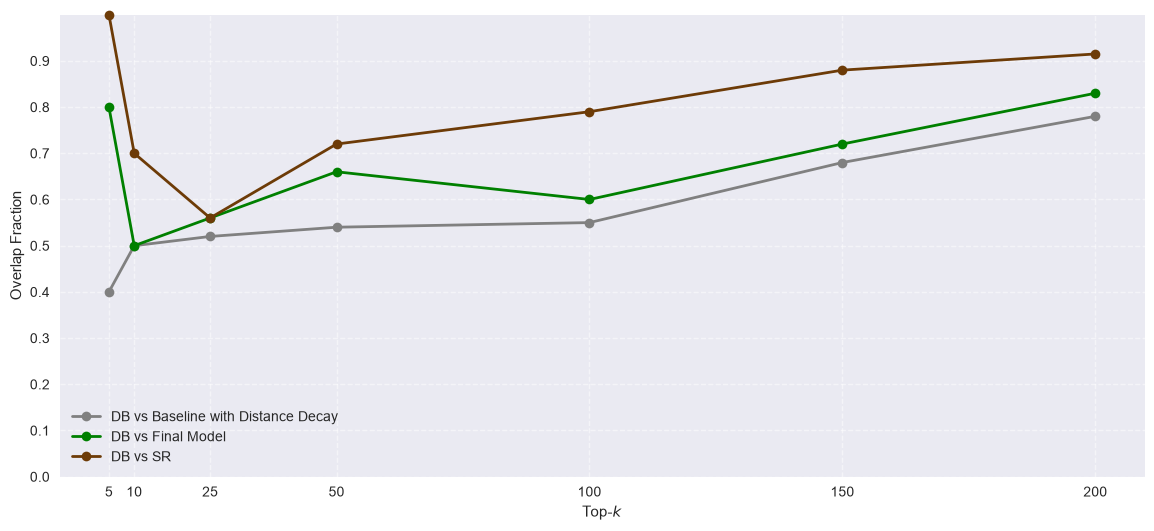

In [23]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

ks = [5, 10, 25, 50, 100, 150, 200]
plt.figure(figsize=(10, 6))

comparisons = {
    "rank_base_dist": "DB vs Baseline with Distance Decay",
    "rank_sim": "DB vs Final Model",
    "rank_sr": "DB vs SR",
}

results = {label: [] for label in comparisons.values()}

for k in ks:
    top_db = set(counts_comp_df.nsmallest(k, "rank_db").index)

    for col, label in comparisons.items():
        top_other = set(counts_comp_df.nsmallest(k, col).index)
        overlap = len(top_db & top_other) / k
        results[label].append(overlap)


colors = ["grey", "green","#6D3B07"]

plt.figure(figsize=(14, 6))
i = 0


for label, overlaps in results.items():
    plt.plot(
        ks,
        overlaps,
        marker="o",
        linewidth=2,
        label=label,clip_on=False, color = colors[i]
    )

    i += 1
plt.yticks(np.arange(0,1, 0.1))
plt.xlabel("Top-$k$")
plt.ylabel("Overlap Fraction")
#plt.title("Top-$k$ Overlap with DB Rad+ Dataset")
plt.xticks(ks)
plt.ylim(0, 1)
plt.grid(True, linestyle="--", alpha=0.5)
plt.legend()
plt.savefig("figures/revision/db_topk_overlap")

import tikzplotlib

tikzplotlib.save("figures/revision/db_topk_overlap.tex")

<Figure size 1000x600 with 0 Axes>

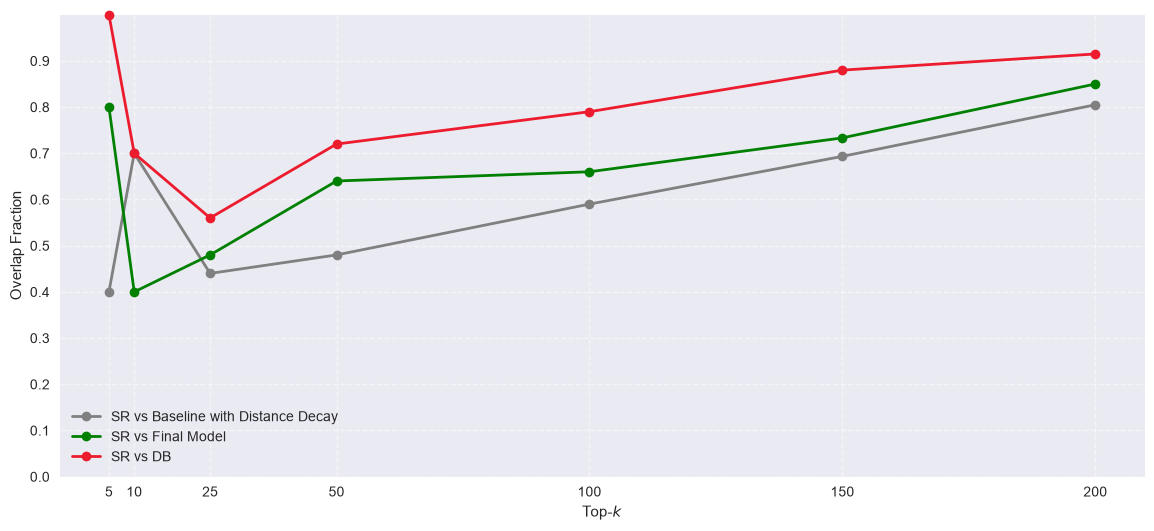

In [24]:
import pandas as pd
import matplotlib.pyplot as plt

ks = [5, 10, 25, 50, 100, 150, 200]
plt.figure(figsize=(10, 6))

comparisons = {
    "rank_base_dist": "SR vs Baseline with Distance Decay",
    "rank_sim": "SR vs Final Model",
    "rank_db": "SR vs DB",
}

results = {label: [] for label in comparisons.values()}

for k in ks:
    top_db = set(counts_comp_df.nsmallest(k, "rank_sr").index)

    for col, label in comparisons.items():
        top_other = set(counts_comp_df.nsmallest(k, col).index)
        overlap = len(top_db & top_other) / k
        results[label].append(overlap)


colors = ["grey", "green","#EC1B2D"]

plt.figure(figsize=(14, 6))
i = 0


for label, overlaps in results.items():
    plt.plot(
        ks,
        overlaps,
        marker="o",
        linewidth=2,
        label=label,clip_on=False, color = colors[i]
    )

    i += 1

plt.xlabel("Top-$k$")
plt.ylabel("Overlap Fraction")
#plt.title("Top-$k$ Overlap with Stadtradeln Dataset")
plt.yticks(np.arange(0,1, 0.1))
plt.xticks(ks)
plt.ylim(0, 1)
plt.grid(True, linestyle="--", alpha=0.5)
plt.legend()
plt.savefig("figures/revision/sr_topk_overlap")

import tikzplotlib

tikzplotlib.save("figures/revision/sr_topk_overlap.tex")

### Counting Stations

In [25]:
import pandas as pd
import geopandas as gpd
query = "SELECT * FROM counting_stations_lines_hamburg"

counts_stations_gdf = gpd.GeoDataFrame.from_postgis(query,engine, geom_col="geometry")
counts_stations_gdf

,id,geometry,count_stations,num_points,count_db,count_sr,count_base,count_sim,count_base_pois,count_base_dist,count_base_non_random_des
0,1,"MULTILINESTRING ((9.96639 53.54083, 9.96662 53...",1268452,3,2816,172,8957,1885,953,1611,1795
1,2,"MULTILINESTRING ((9.93399 53.55036, 9.93402 53...",2578092,3,2402,512,1925,1944,1009,455,2144
2,6,"MULTILINESTRING ((9.98975 53.55962, 9.99019 53...",2409702,3,4066,458,583,1742,861,429,1684
3,7,"MULTILINESTRING ((9.99572 53.55938, 9.99604 53...",1512093,1,5841,613,361,1108,579,292,1090
4,8,"MULTILINESTRING ((10.01994 53.56622, 10.01995 ...",449786,3,585,79,43,151,65,44,208
5,9,"MULTILINESTRING ((9.99897 53.58, 9.99923 53.57...",3538866,3,8208,978,1174,3303,1381,665,2810
6,10,"MULTILINESTRING ((9.99957 53.58057, 9.99944 53...",1903830,3,4481,554,534,774,477,272,927
7,11,"MULTILINESTRING ((9.97072 53.58164, 9.971 53.5...",1666940,3,1441,149,157,880,209,84,599
8,12,"MULTILINESTRING ((9.9728 53.58151, 9.97237 53....",3071310,3,2519,484,2685,2175,1237,839,2301
9,21,"MULTILINESTRING ((9.99797 53.55786, 9.9978 53....",2072322,2,10289,1176,8401,4763,2808,2145,5444


In [26]:
counts_stations_gdf["rank_real"] = counts_stations_gdf["count_stations"].rank(ascending=False)
counts_stations_gdf["rank_db"] = counts_stations_gdf["count_db"].rank(ascending=False)
counts_stations_gdf["rank_base"] = counts_stations_gdf["count_base"].rank(ascending=False)
counts_stations_gdf["rank_sim"] = counts_stations_gdf["count_sim"].rank(ascending=False)
counts_stations_gdf["rank_sr"] = counts_stations_gdf["count_sr"].rank(ascending=False)
counts_stations_gdf["rank_base_dist"] = counts_stations_gdf["count_base_dist"].rank(ascending=False)
counts_stations_gdf["rank_base_pois"] = counts_stations_gdf["count_base_pois"].rank(ascending=False)
counts_stations_gdf["rank_base_non_random_des"] = counts_stations_gdf["count_base_non_random_des"].rank(ascending=False)

In [27]:
counts_stations_gdf["count_aadt"] =  counts_stations_gdf["count_stations"] / 365
counts_stations_gdf[["count_stations","count_db","count_sr","count_base","count_base_dist","count_base_pois","count_base_non_random_des","count_sim"]].corr()

,count_stations,count_db,count_sr,count_base,count_base_dist,count_base_pois,count_base_non_random_des,count_sim
count_stations,1.000000,0.602445,0.684139,0.090610,0.265661,0.535051,0.543568,0.610002
count_db,0.602445,1.000000,0.929065,0.390361,0.581753,0.767515,0.767471,0.796842
count_sr,0.684139,0.929065,1.000000,0.279338,0.506444,0.778338,0.783415,0.804580
count_base,0.090610,0.390361,0.279338,1.000000,0.957341,0.707664,0.703769,0.665530
count_base_dist,0.265661,0.581753,0.506444,0.957341,1.000000,0.869461,0.862518,0.833442
count_base_pois,0.535051,0.767515,0.778338,0.707664,0.869461,1.000000,0.995780,0.979276
count_base_non_random_des,0.543568,0.767471,0.783415,0.703769,0.862518,0.995780,1.000000,0.985181
count_sim,0.610002,0.796842,0.804580,0.665530,0.833442,0.979276,0.985181,1.000000


P-values
rank_base                   0.423503
rank_base_dist              0.067006
rank_base_pois              0.001608
rank_base_non_random_des    0.001536
rank_sim                    0.000693
rank_sr                     0.000180
rank_db                     0.000136
Name: rank_real, dtype: float64


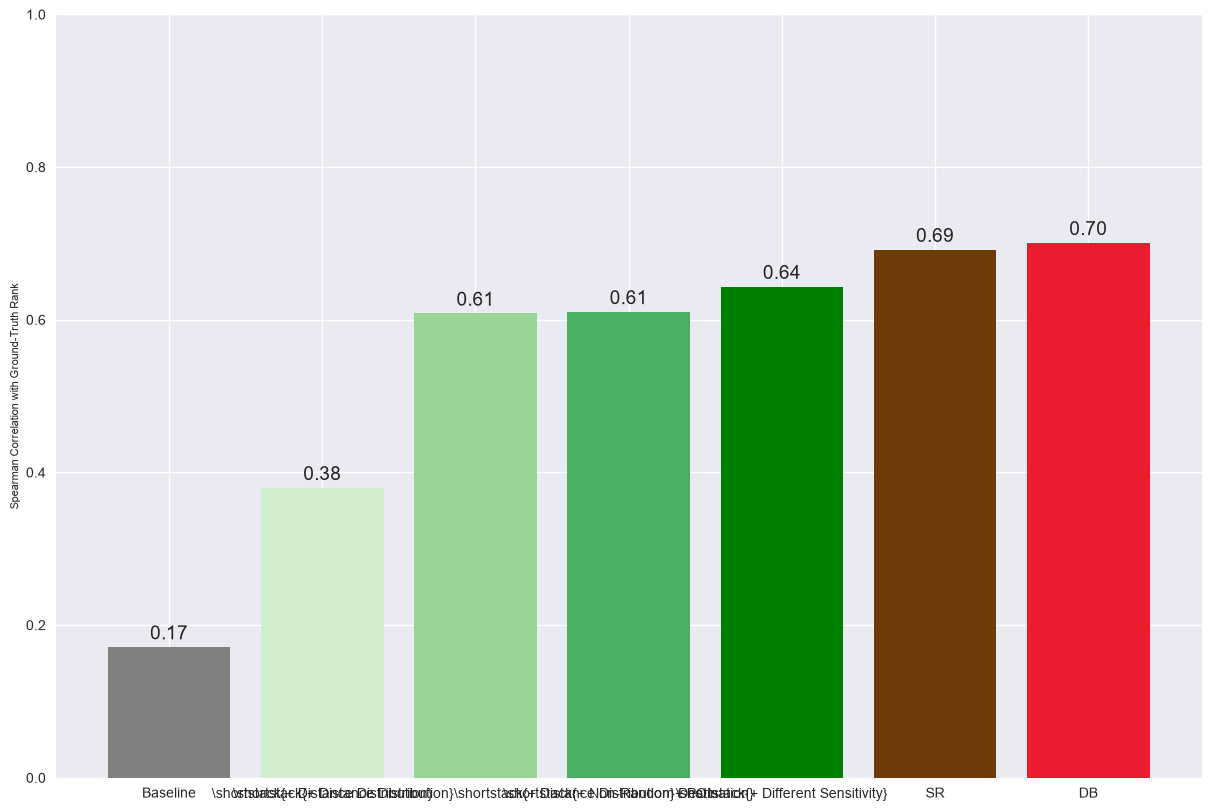

In [29]:
import seaborn as sns
import textwrap
import matplotlib.pyplot as plt
from scipy.stats import spearmanr, kendalltau, pearsonr
import numpy as np

plt.figure(figsize=(12, 8))

plt.style.use('seaborn-v0_8')
plt.rcParams['figure.constrained_layout.use'] = True


rank_df = counts_stations_gdf[["rank_real", "rank_base","rank_base_dist","rank_base_pois","rank_base_non_random_des","rank_sim","rank_sr","rank_db"]]

corrs = (
    rank_df
    .corr()["rank_real"]
    .drop("rank_real")
)


corr_matrix, p_matrix = spearmanr(rank_df)


pval_df = pd.DataFrame(p_matrix,
                       index=rank_df.columns,
                       columns=rank_df.columns)
print("P-values")
print(pval_df["rank_real"]
    .drop("rank_real"))

labels = ["Baseline", r"\shortstack{+ Distance Distribution}", 
          r"\shortstack{+ Distance Distribution}"r"\shortstack{+ Distance Distribution}""+ POIs", r"\shortstack{+ Non-Random Destination}",
          r"\shortstack{+ Different Sensitivity}",
          "SR","DB"]

middle_colors = plt.cm.Greens(np.linspace(0.2, 0.6, 3))

colors = (
    ["gray"] +                    
    list(middle_colors) +         
    ["green", "#6D3B07", "#EC1B2D"]    
)
plt.bar(
    x=labels,
    height=corrs.values, color=colors)

for i, v in enumerate(corrs.values):
    plt.text(i, v + 0.01, f"{v:.2f}", ha="center", fontsize=14)

plt.ylim(0, 1)
plt.ylabel("Spearman Correlation with Ground-Truth Rank", fontsize = 8)
# plt.xlabel("Method")
# plt.xticks(rotation=45, ha="right")
plt.savefig("figures/revision/hamburg_spearman")

plt.ylabel("Spearman Correlation with Ground-Truth Rank")
 # plt.xlabel("Method")
plt.savefig("figures/revision/hamburg_spearman")
import tikzplotlib

# plt.tight_layout()

tikzplotlib.save("figures/revision/hamburg_spearman.tex",     extra_axis_parameters=[
                r"xticklabel style={font=\fontsize{6}{10}\selectfont, rotate=45, anchor=east}",
                r"ylabel style={font=\fontsize{8}{10}\selectfont}"]
)

rank_base                   0.389341
rank_base_dist              0.087028
rank_base_pois              0.003696
rank_base_non_random_des    0.003564
rank_sim                    0.002082
rank_sr                     0.001371
rank_db                     0.000966
Name: rank_real, dtype: float64


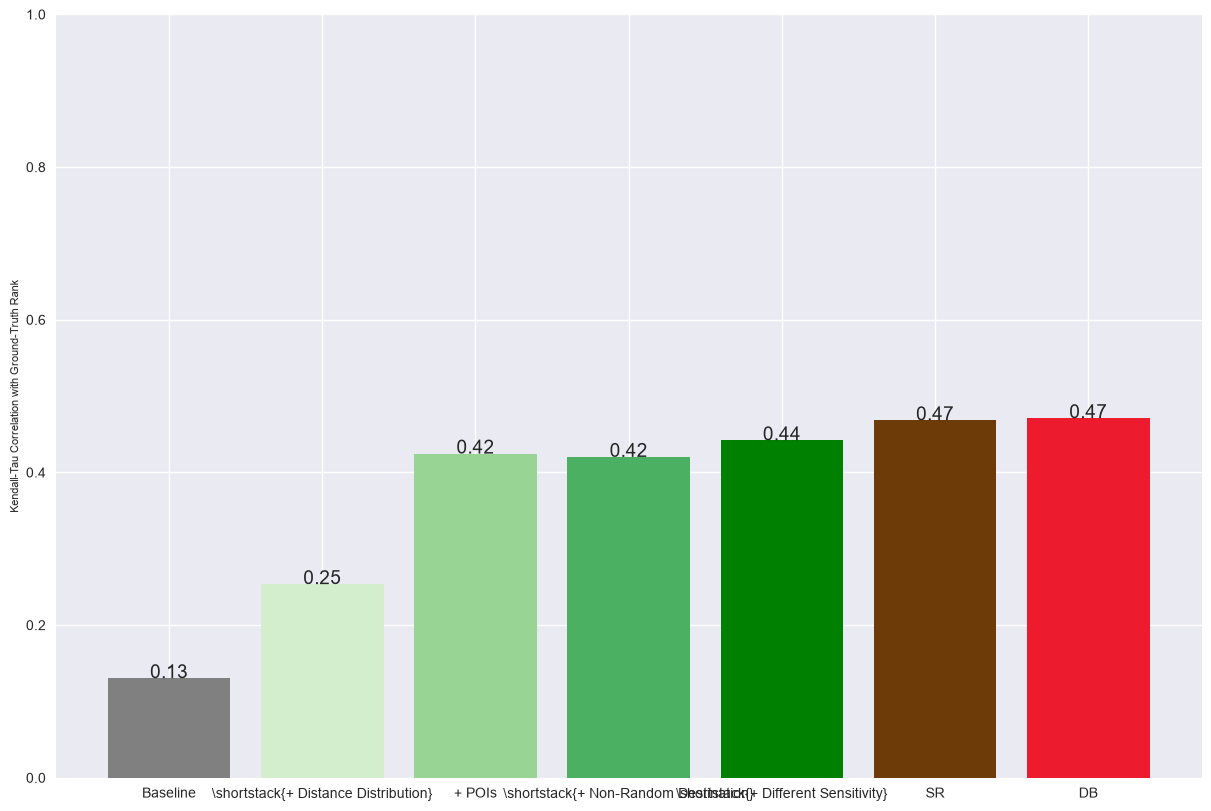

In [33]:
import seaborn as sns
import textwrap


plt.figure(figsize=(12, 8))

plt.style.use('seaborn-v0_8')

corrs = (
    counts_stations_gdf[["rank_real", "rank_base","rank_base_dist", "rank_base_pois","rank_base_non_random_des","rank_sim","rank_sr","rank_db"]]
    .corr(method="kendall")["rank_real"]
    .drop("rank_real")
)

rank_df = counts_stations_gdf[["rank_real", "rank_base","rank_base_dist","rank_base_pois","rank_base_non_random_des","rank_sim","rank_sr","rank_db"]]


cols = rank_df.columns

corr_matrix = pd.DataFrame(index=cols, columns=cols, dtype=float)
p_matrix = pd.DataFrame(index=cols, columns=cols, dtype=float)

for c1 in cols:
    for c2 in cols:
        tau, pval = kendalltau(rank_df[c1], rank_df[c2])

        corr_matrix.loc[c1, c2] = tau
        p_matrix.loc[c1, c2] = pval

pval_df = pd.DataFrame(p_matrix, index=cols,columns=cols)



print(pval_df["rank_real"]
    .drop("rank_real"))


labels = ["Baseline",r"\shortstack{+ Distance Distribution}","+ POIs", r"\shortstack{+ Non-Random Destination}",
          r"\shortstack{+ Different Sensitivity}",
          "SR","DB"]

middle_colors = plt.cm.Greens(np.linspace(0.2, 0.6, 3))

colors = (
    ["gray"] +                    
    list(middle_colors) +         
    ["green", "#6D3B07", "#EC1B2D"]    
)
plt.bar(
    x=labels,
    height=corrs.values, color=colors)


for i, v in enumerate(corrs.values):
    # plt.text(i, v + 0.01, f"{v:.2f}", ha="center", fontsize=14)
    plt.text(i, v, f"{v:.2f}", ha="center", fontsize=14)

plt.ylim(0, 1)
plt.ylabel("Kendall-Tau Correlation with Ground-Truth Rank", fontsize = 8)
# plt.xlabel("Method")
#plt.xticks(rotation=45, ha="right", fontsize=6)

plt.savefig("figures/revision/hamburg_kendalltau")

import tikzplotlib
tikzplotlib.save("figures/revision/hamburg_kendalltau.tex",     extra_axis_parameters=[
                r"xticklabel style={font=\fontsize{6}{10}\selectfont, rotate=45, anchor=east}",
                r"ylabel style={font=\fontsize{8}{10}\selectfont}"]
)

p-values
count_base                   0.673705
count_base_dist              0.209593
count_base_pois              0.007059
count_base_non_random_des    0.006045
count_sim                    0.001551
count_sr                     0.000227
count_db                     0.001837
Name: count_stations, dtype: float64


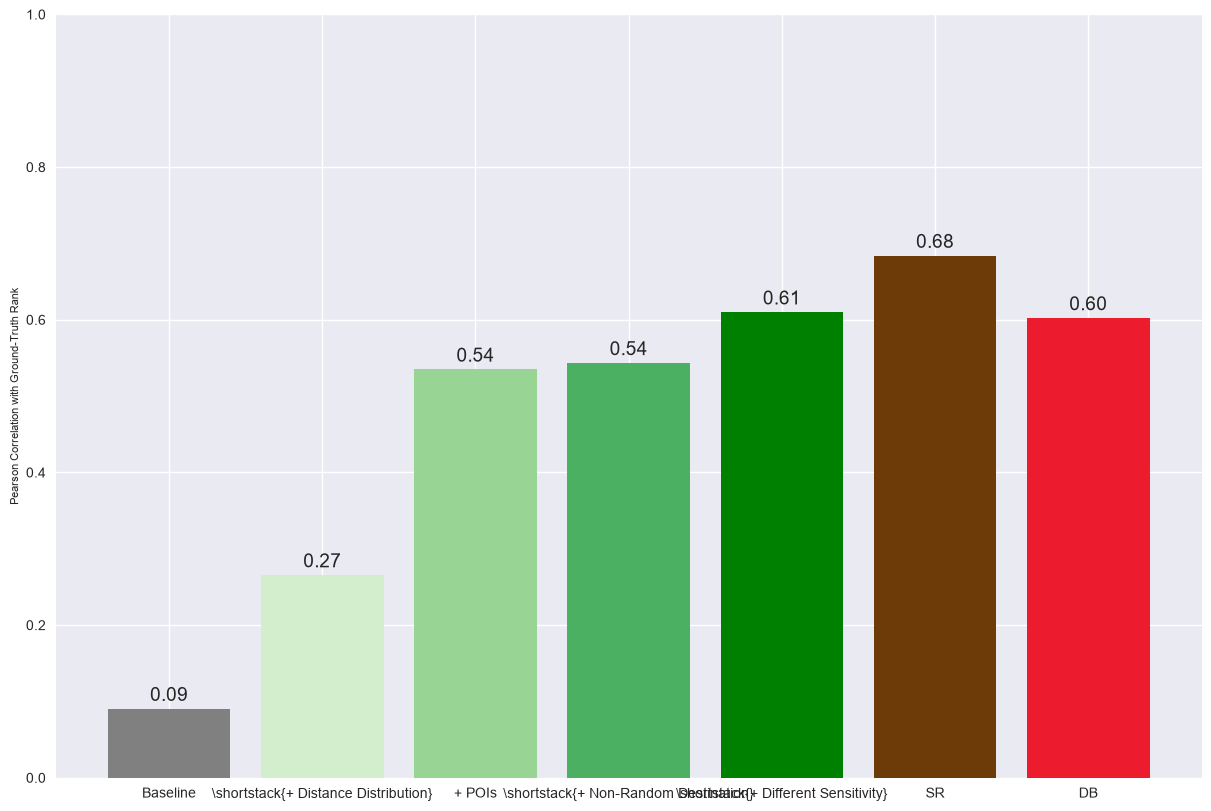

In [35]:
import seaborn as sns
import textwrap

fig, ax = plt.subplots(figsize=(12, 8))

plt.style.use('seaborn-v0_8')

corrs = (
    counts_stations_gdf[["count_stations", "count_base", "count_base_dist","count_base_pois","count_base_non_random_des","count_sim","count_sr","count_db"]]
    .corr()["count_stations"]
    .drop("count_stations")
)

count_df = counts_stations_gdf[["count_stations", "count_base", "count_base_dist","count_base_pois","count_base_non_random_des","count_sim","count_sr","count_db"]]


cols = count_df.columns

corr_matrix = pd.DataFrame(index=cols, columns=cols, dtype=float)
p_matrix = pd.DataFrame(index=cols, columns=cols, dtype=float)

for c1 in cols:
    for c2 in cols:
        tau, pval = pearsonr(count_df[c1], count_df[c2])

        corr_matrix.loc[c1, c2] = tau
        p_matrix.loc[c1, c2] = pval

pval_df = pd.DataFrame(p_matrix, index=cols,columns=cols)


print("p-values")
print(pval_df["count_stations"]
    .drop("count_stations"))


labels = ["Baseline",r"\shortstack{+ Distance Distribution}", "+ POIs", r"\shortstack{+ Non-Random Destination}",
          r"\shortstack{+ Different Sensitivity}",
          "SR","DB"]

middle_colors = plt.cm.Greens(np.linspace(0.2, 0.6, 3))

colors = (
    ["gray"] +                    
    list(middle_colors) +         
    ["green", "#6D3B07", "#EC1B2D"]    
)
plt.bar(
    x=labels,
    height=corrs.values, color=colors)


for i, v in enumerate(corrs.values):
    plt.text(i, v + 0.01, f"{v:.2f}", ha="center", fontsize=14)

plt.ylim(0, 1)
plt.ylabel("Pearson Correlation with Ground-Truth Rank", fontsize = 8)
# plt.xlabel("Method")
#plt.xticks(rotation=45, ha="right", fontsize=6)

plt.savefig("figures/revision/hamburg_pearson")

import tikzplotlib

tikzplotlib.save("figures/revision/hamburg_pearson.tex")


tikzplotlib.save("figures/revision/hamburg_pearson.tex",     extra_axis_parameters=[
                r"xticklabel style={font=\fontsize{6}{10}\selectfont, rotate=45, anchor=east}",
                r"ylabel style={font=\fontsize{8}{10}\selectfont}"]
)

In [23]:
## TODO: Add p-values